# Clustering Pelanggan Mall dengan DBSCAN, BIRCH, dan EM

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032 |

## Deskripsi Tugas

Pada tugas ini dilakukan clustering pada data pelanggan mall menggunakan DBSCAN, BIRCH, dan Gaussian Mixture Model dengan metode EM.

Dataset berisi data pelanggan pusat perbelanjaan. Fitur yang digunakan adalah:
- Annual Income (k$)
- Spending Score (1-100)

CustomerID adalah identitas pelanggan dan tidak digunakan sebagai fitur. Gender tidak digunakan dalam clustering.

Dataset dibaca dari file data.csv yang berada di folder yang sama dengan notebook.

## Tahapan

1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM dengan Gaussian Mixture Model.
6. Evaluasi model.
7. Analisis dan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

Periksa isi dataset, tipe data, statistik deskriptif, missing value, duplikasi, dan distribusi fitur. Scatter plot digunakan untuk melihat pola awal pelanggan.

Aturan IQR menandai dua nilai Annual Income sebesar 137, yaitu CustomerID 199 dan 200. Nilai ini tidak dihapus karena belum ada bukti bahwa data tersebut salah.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
df = pd.read_csv("data.csv")
print(df.shape)
display(df.head())
df.info()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [3]:
display(df.describe())

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
display(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [5]:
print("Baris duplikat:", df.duplicated().sum())

Baris duplikat: 0


In [6]:
display(df["Gender"].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64

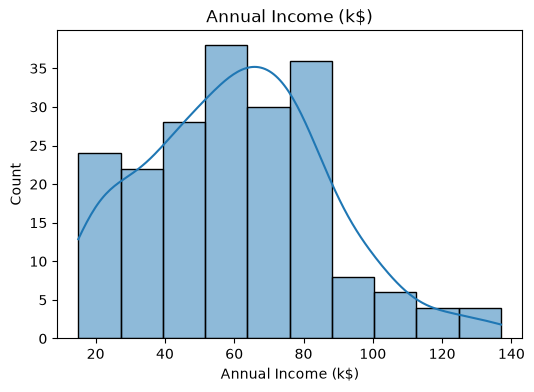

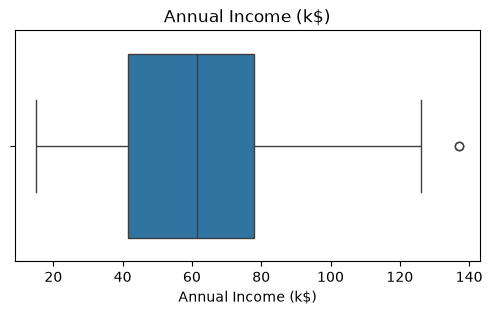

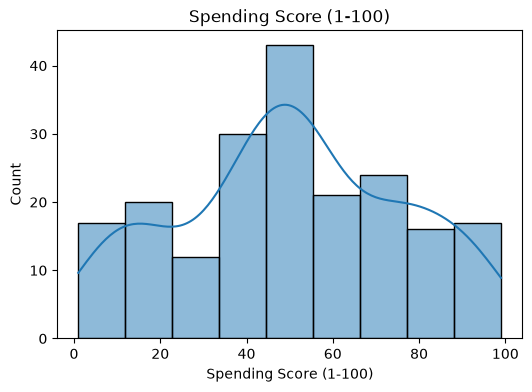

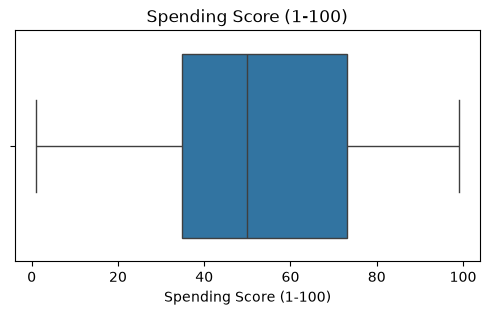

In [7]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[feature], kde=True)
    plt.title(feature)
    plt.show()

    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[feature])
    plt.title(feature)
    plt.show()

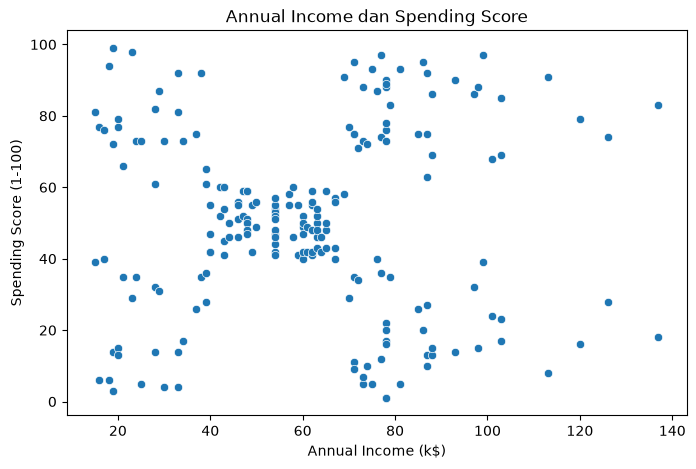

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=features[0], y=features[1])
plt.title("Annual Income dan Spending Score")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

Jawaban:

Tidak ada missing value maupun baris duplikat. Annual Income berkisar dari 15 sampai 137 k$, sedangkan Spending Score berkisar dari 1 sampai 99. Scatter plot menunjukkan beberapa kelompok, termasuk pelanggan dengan pendapatan tinggi dan spending score rendah maupun tinggi. Dua nilai pendapatan 137 terdeteksi oleh aturan IQR, tetapi tetap dipertahankan karena tidak terbukti sebagai kesalahan data.

# 2. Preprocessing

Gunakan Annual Income dan Spending Score sebagai fitur. CustomerID tidak digunakan karena hanya berfungsi sebagai identitas. StandardScaler digunakan agar skala kedua fitur sebanding.

In [9]:
X = df[features]

q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < (q1 - 1.5 * iqr)) | (X > (q3 + 1.5 * iqr))).sum()
display(outliers)

Annual Income (k$)        2
Spending Score (1-100)    0
dtype: int64

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features)
display(X_scaled.head())
display(X_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


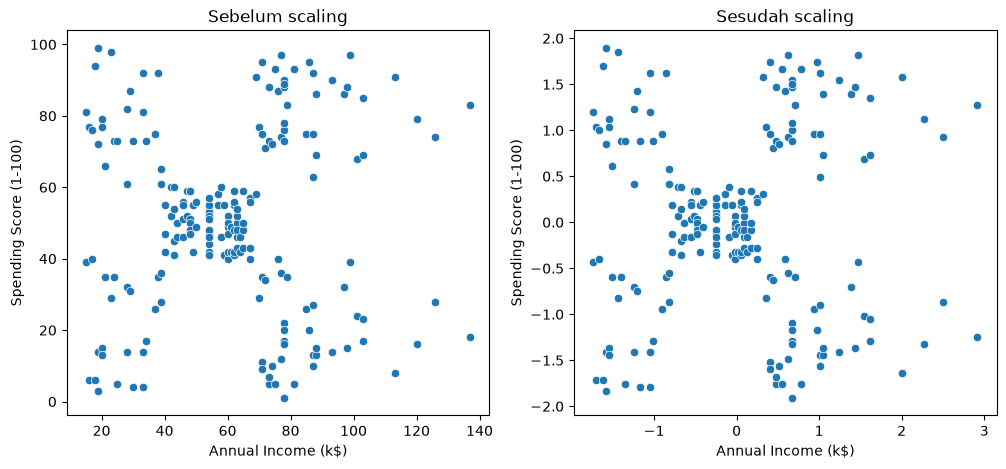

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=X, x=features[0], y=features[1], ax=axes[0])
axes[0].set_title("Sebelum scaling")
sns.scatterplot(data=X_scaled, x=features[0], y=features[1], ax=axes[1])
axes[1].set_title("Sesudah scaling")
plt.show()

Fitur yang digunakan: Annual Income (k$) dan Spending Score (1-100).

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa CustomerID tidak digunakan.

Jawaban:

Kedua fitur menggambarkan aspek pelanggan yang digunakan untuk segmentasi dan dapat divisualisasikan dalam scatter plot. CustomerID hanya nomor identitas dan tidak menggambarkan karakteristik pelanggan.

# 3. Eksperimen DBSCAN

DBSCAN membentuk cluster berdasarkan kepadatan data. Parameter eps mengatur jarak antar titik dan min_samples mengatur jumlah minimum tetangga. Data yang tidak masuk cluster diberi label -1.

DBSCAN tidak perlu menentukan jumlah cluster di awal. Hasilnya dipengaruhi oleh nilai eps dan min_samples.

In [12]:
dbscan = DBSCAN(eps=0.45, min_samples=10)
labels_dbscan = dbscan.fit_predict(X_scaled)
print("Jumlah cluster:", len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))
print("Jumlah noise:", list(labels_dbscan).count(-1))

Jumlah cluster: 5
Jumlah noise: 29


In [13]:
display(pd.Series(labels_dbscan).value_counts().sort_index())

-1    29
 0    16
 1    10
 2    92
 3    30
 4    23
Name: count, dtype: int64

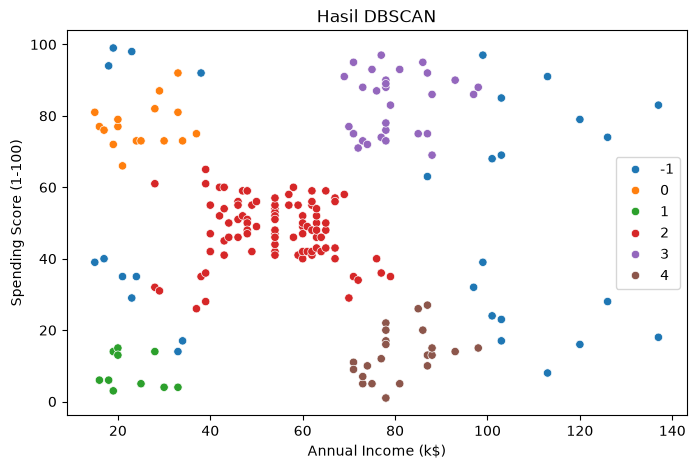

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X[features[0]], y=X[features[1]], hue=labels_dbscan, palette="tab10")
plt.title("Hasil DBSCAN")
plt.show()

In [15]:
hasil_dbscan = []

for eps in [0.3, 0.4, 0.45, 0.5, 0.6]:
    for min_samples in [5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise = list(labels).count(-1)
        mask = labels != -1
        score = np.nan
        if len(set(labels[mask])) > 1:
            score = silhouette_score(X_scaled[mask], labels[mask])
        hasil_dbscan.append([eps, min_samples, n_clusters, noise, score])

display(pd.DataFrame(hasil_dbscan, columns=["eps", "min_samples", "cluster", "noise", "silhouette"]))

,eps,min_samples,cluster,noise,silhouette
0,0.30,5,7,35,0.524328
1,0.30,10,4,88,0.607301
2,0.40,5,4,15,0.478059
3,0.40,10,4,51,0.597195
4,0.45,5,3,11,0.353641
5,0.45,10,5,29,0.573635
6,0.50,5,2,8,0.387558
7,0.50,10,4,21,0.510668
8,0.60,5,1,5,NaN
9,0.60,10,1,10,NaN


disini saya memilih eps 45 dan min sample 10 karena cocok dengan hasil model lain yang memiliki 5 cluster, dan memiliki tingkat kecocokan sebesar 0.57

### Analisis DBSCAN

- Apa pengaruh kenaikan eps terhadap jumlah cluster dan noise?
- Apa pengaruh min_samples?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

Jawaban:

Pada min_samples=5, kenaikan eps dari 0.30 ke 0.50 menurunkan jumlah cluster dari 7 menjadi 2 dan noise dari 35 menjadi 8. Pada eps=0.30, kenaikan min_samples dari 5 ke 10 menurunkan cluster dari 7 menjadi 4 dan menaikkan noise dari 35 menjadi 88. eps=0.60 menghasilkan satu cluster. eps=0.30 dan min_samples=10 menghasilkan 88 noise, yaitu 44 persen data, walaupun Silhouette-nya 0.607. Parameter yang digunakan adalah eps=0.45 dan min_samples=10. Hasilnya 5 cluster, 29 noise, dan Silhouette 0.574.

# 4. Eksperimen BIRCH

BIRCH membuat subcluster berdasarkan threshold. Parameter n_clusters digunakan untuk menentukan jumlah cluster akhir.

BIRCH tidak memberi label noise. Perubahan threshold dapat mengubah jumlah subcluster.

In [16]:
birch = Birch(threshold=0.1, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah cluster:", len(set(labels_birch)))

Jumlah cluster: 5


In [17]:
display(pd.Series(labels_birch).value_counts().sort_index())

0    39
1    85
2    32
3    21
4    23
Name: count, dtype: int64

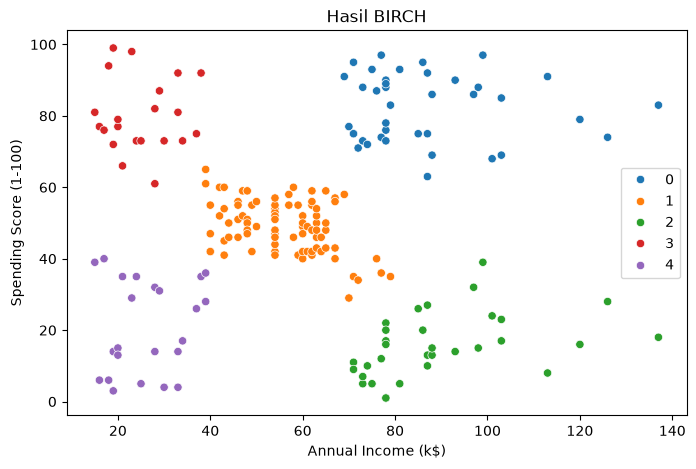

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X[features[0]], y=X[features[1]], hue=labels_birch, palette="tab10")
plt.title("Hasil BIRCH")
plt.show()

In [19]:
hasil_birch = []

for threshold in [0.1, 0.3, 0.5, 0.7, 1.0]:
    labels = Birch(threshold=threshold).fit_predict(X_scaled)
    n_clusters = len(set(labels))
    score = silhouette_score(X_scaled, labels) if n_clusters > 1 else np.nan
    hasil_birch.append([threshold, n_clusters, score])

display(pd.DataFrame(hasil_birch, columns=["threshold", "cluster", "silhouette"]))

,threshold,cluster,silhouette
0,0.1,3,0.461048
1,0.3,3,0.466585
2,0.5,3,0.338191
3,0.7,3,0.461048
4,1.0,3,0.400063


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika threshold diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika n_clusters ditentukan?

Jawaban:

Pada uji threshold, jumlah cluster tetap 3 karena n_clusters tidak diberikan dan nilai default BIRCH adalah 3. Silhouette tertinggi pada uji tersebut adalah 0.467 saat threshold=0.3. Model utama memakai threshold=0.1 dan n_clusters=5, menghasilkan 5 cluster dengan Silhouette 0.554. BIRCH memberi label cluster kepada seluruh pelanggan, sedangkan DBSCAN menandai 29 pelanggan sebagai noise. Saat n_clusters ditentukan, jumlah cluster akhir mengikuti nilai tersebut.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Gaussian Mixture Model menggunakan EM untuk memperkirakan distribusi dan keanggotaan data pada setiap komponen.

Parameter n_components menentukan jumlah komponen Gaussian. Probabilitas keanggotaan menunjukkan peluang data berada pada setiap komponen.

In [20]:
gmm = GaussianMixture(n_components=5, random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Jumlah cluster:", len(set(labels_gmm)))

Jumlah cluster: 5


In [21]:
display(pd.Series(labels_gmm).value_counts().sort_index())
probabilitas = gmm.predict_proba(X_scaled)
display(pd.DataFrame(probabilitas).head())

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

,0,1,2,3,4
0,1.576897e-05,1.880092e-08,9.520312e-04,5.200131e-08,0.999032
1,1.627762e-05,1.895968e-04,9.997902e-01,4.210134e-23,0.000004
2,2.213394e-19,9.526157e-19,1.225495e-12,1.862233e-04,0.999814
3,1.054448e-04,1.800877e-04,9.996937e-01,3.793901e-21,0.000021
4,6.473014e-05,3.842732e-08,1.556695e-03,4.757227e-08,0.998378


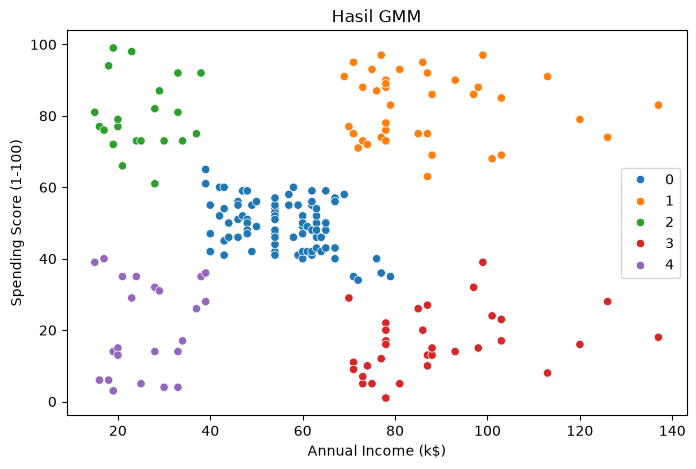

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X[features[0]], y=X[features[1]], hue=labels_gmm, palette="tab10")
plt.title("Hasil GMM")
plt.show()

In [23]:
hasil_gmm = []

for n in range(2, 9):
    model = GaussianMixture(n_components=n, random_state=42)
    model.fit(X_scaled)
    labels = model.predict(X_scaled)
    score = silhouette_score(X_scaled, labels) if len(set(labels)) > 1 else np.nan
    hasil_gmm.append([n, score, model.bic(X_scaled)])

display(pd.DataFrame(hasil_gmm, columns=["n_components", "silhouette", "BIC"]))

,n_components,silhouette,BIC
0,2,0.379082,1153.904655
1,3,0.430190,1151.718274
2,4,0.413392,1103.790149
3,5,0.553689,1058.652252
4,6,0.516982,1074.682807
5,7,0.509057,1087.328517
6,8,0.430210,1102.370701


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika n_components diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

Jawaban:

Probabilitas keanggotaan menunjukkan peluang pelanggan berada pada setiap komponen Gaussian. Pada lima baris pertama, probabilitas tertinggi berkisar sekitar 0.998 sampai 1.000. Perubahan n_components mengubah pembagian pelanggan dan nilai evaluasi. Jumlah komponen perlu ditentukan sebelum pelatihan karena GMM membuat sejumlah distribusi Gaussian sesuai nilai tersebut. Pada hasil ini, 5 komponen memiliki Silhouette tertinggi sebesar 0.554 dan BIC terendah sebesar 1058.652.

# 6. Evaluasi dan Perbandingan Model

Gunakan Silhouette, Davies-Bouldin, dan Calinski-Harabasz untuk membandingkan hasil. Untuk DBSCAN, keluarkan noise dari perhitungan metrik.

Silhouette yang lebih tinggi, Davies-Bouldin yang lebih rendah, dan Calinski-Harabasz yang lebih tinggi biasanya menunjukkan hasil yang lebih baik.

In [24]:
models = {
    "DBSCAN": labels_dbscan,
    "BIRCH": labels_birch,
    "GMM": labels_gmm,
}

In [25]:
hasil_evaluasi = []

for nama, labels in models.items():
    mask = labels != -1 if nama == "DBSCAN" else np.ones(len(labels), dtype=bool)
    labels_valid = labels[mask]
    data_valid = X_scaled[mask]
    n_clusters = len(set(labels_valid))
    noise = list(labels).count(-1) if nama == "DBSCAN" else 0
    silhouette = np.nan
    davies_bouldin = np.nan
    calinski_harabasz = np.nan

    if 1 < n_clusters < len(labels_valid):
        silhouette = silhouette_score(data_valid, labels_valid)
        davies_bouldin = davies_bouldin_score(data_valid, labels_valid)
        calinski_harabasz = calinski_harabasz_score(data_valid, labels_valid)

    hasil_evaluasi.append([nama, n_clusters, noise, silhouette, davies_bouldin, calinski_harabasz])

display(pd.DataFrame(hasil_evaluasi, columns=["model", "cluster", "noise", "silhouette", "davies_bouldin", "calinski_harabasz"]))

,model,cluster,noise,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,5,29,0.573635,0.483029,245.143859
1,BIRCH,5,0,0.553809,0.577862,244.410326
2,GMM,5,0,0.553689,0.576010,244.940197


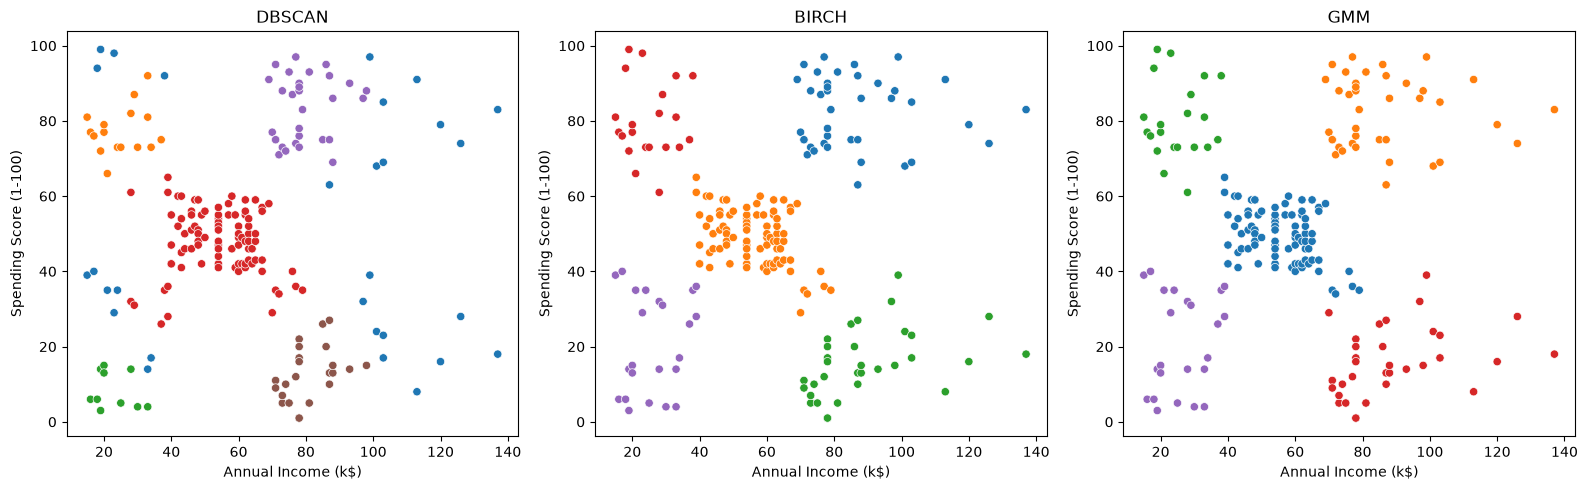

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nama, labels) in zip(axes, models.items()):
    sns.scatterplot(x=X[features[0]], y=X[features[1]], hue=labels, palette="tab10", ax=ax, legend=False)
    ax.set_title(nama)

plt.tight_layout()
plt.show()

In [27]:
for nama, labels in models.items():
    print(nama)
    profil = X.copy()
    profil["cluster"] = labels
    display(profil.groupby("cluster").agg(["count", "mean", "median"]))

DBSCAN


Annual Income (k$)                   Spending Score (1-100)  \
                     count       mean median                  count   
cluster                                                               
-1                      29  77.689655   99.0                     29   
 0                      16  25.062500   24.5                     16   
 1                      10  22.800000   20.0                     10   
 2                      92  54.152174   54.0                     92   
 3                      30  79.533333   78.0                     30   
 4                      23  80.956522   78.0                     23   

                           
              mean median  
cluster                    
-1       51.931034   39.0  
 0       77.312500   76.5  
 1        8.400000    6.0  
 2       48.097826   48.5  
 3       83.133333   86.0  
 4       12.782609   13.0

BIRCH


Annual Income (k$)                   Spending Score (1-100)  \
                     count       mean median                  count   
cluster                                                               
0                       39  86.538462   79.0                     39   
1                       85  55.811765   57.0                     85   
2                       32  89.406250   86.5                     32   
3                       21  25.095238   24.0                     21   
4                       23  26.304348   25.0                     23   

                           
              mean median  
cluster                    
0        82.128205   83.0  
1        49.129412   49.0  
2        15.593750   15.0  
3        80.047619   77.0  
4        20.913043   17.0

GMM


Annual Income (k$)                   Spending Score (1-100)  \
                     count       mean median                  count   
cluster                                                               
0                       84  55.642857   55.5                     84   
1                       39  86.538462   79.0                     39   
2                       21  25.095238   24.0                     21   
3                       33  88.818182   86.0                     33   
4                       23  26.304348   25.0                     23   

                           
              mean median  
cluster                    
0        49.369048   49.5  
1        82.128205   83.0  
2        80.047619   77.0  
3        16.000000   15.0  
4        20.913043   17.0

### Ringkasan Perbandingan

Bandingkan DBSCAN, BIRCH, dan EM/GMM berdasarkan aspek berikut:


| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional melalui n_clusters | Ya, melalui n_components |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | eps dan min_samples | threshold dan n_clusters | n_components |
| Bentuk cluster yang dapat dimodelkan | Berdasarkan kepadatan | Subcluster yang diringkas dan digabung | Mengikuti distribusi Gaussian |
| Kelebihan | Menemukan noise dan tidak perlu jumlah cluster awal | Merangkum data dan memberi label ke semua pelanggan | Memberi probabilitas keanggotaan |
| Kekurangan | Sensitif terhadap parameter dan kepadatan | Tidak menandai noise dan hasil dipengaruhi threshold | Jumlah komponen harus ditentukan |

# 7. Analisis

Bandingkan hasil model, visualisasi, metrik evaluasi, dan profil cluster. Gunakan median pendapatan dan spending score untuk menjelaskan karakter setiap cluster.

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter threshold dan n_clusters memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

Jawaban:

1. Scaling menyamakan skala fitur agar rentang Annual Income yang lebih besar tidak mendominasi perhitungan jarak.
2. Pada min_samples=5, eps=0.30 menghasilkan 7 cluster dan 35 noise, sedangkan eps=0.50 menghasilkan 2 cluster dan 8 noise. Pada eps=0.30, min_samples=10 menghasilkan 4 cluster dan 88 noise. Parameter yang dipakai, eps=0.45 dan min_samples=10, menghasilkan 5 cluster dan 29 noise.
3. Pada uji threshold, jumlah cluster tetap 3 karena n_clusters tidak diatur dan nilai default BIRCH adalah 3. Model utama memakai threshold=0.1 dan n_clusters=5, menghasilkan 5 cluster.
4. Probabilitas GMM menunjukkan peluang pelanggan menjadi anggota tiap komponen. EM berulang kali memperbarui probabilitas keanggotaan dan parameter Gaussian sampai konvergen.
5. BIRCH mudah diinterpretasikan untuk membagi seluruh pelanggan menjadi 5 cluster. GMM menghasilkan pembagian yang mirip dan juga menyediakan probabilitas keanggotaan. DBSCAN berguna untuk menemukan noise.
6. DBSCAN memperoleh Silhouette 0.574, Davies-Bouldin 0.483, dan Calinski-Harabasz 245.144. BIRCH memperoleh 0.554, 0.578, dan 244.410. GMM memperoleh 0.554, 0.576, dan 244.940. Metrik DBSCAN dihitung hanya pada 171 pelanggan non-noise, sedangkan BIRCH dan GMM memakai seluruh 200 pelanggan, sehingga hasilnya tidak sepenuhnya sebanding.
7. Profil BIRCH dan GMM menunjukkan kelompok pendapatan menengah dengan spending menengah, kelompok pendapatan rendah dengan spending rendah atau tinggi, serta kelompok pendapatan tinggi dengan spending rendah atau tinggi. Median kelompok menengah sekitar 55 sampai 57 k$ dan spending sekitar 49 sampai 50. Kelompok pendapatan tinggi memiliki median sekitar 79 sampai 86 k$, dengan spending sekitar 15 atau 83. DBSCAN juga membentuk kelompok, tetapi 29 pelanggan menjadi noise.
8. Analisis hanya menggunakan dua fitur dan 200 pelanggan. Informasi usia, gender, dan riwayat transaksi belum digunakan. Hasil juga dapat berubah jika parameter atau dataset berubah.

# 8. Kesimpulan dan Saran

Tuliskan algoritma yang paling sesuai berdasarkan hasil eksperimen, parameter yang digunakan, perbedaan algoritma, dan saran eksperimen berikutnya.

Tuliskan kesimpulan berdasarkan eksperimen:

- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

Jawaban:

BIRCH dengan threshold=0.1 dan n_clusters=5 mudah digunakan untuk membagi semua pelanggan menjadi lima cluster. GMM dengan 5 komponen memberi hasil hampir sama dan memiliki BIC terendah sebesar 1058.652. DBSCAN menggunakan eps=0.45 dan min_samples=10, menghasilkan 5 cluster, 29 noise, dan Silhouette 0.574. DBSCAN menemukan noise, BIRCH merangkum data menjadi subcluster, sedangkan GMM membentuk distribusi Gaussian dan menghasilkan probabilitas keanggotaan. Eksperimen berikutnya dapat menambahkan fitur seperti Age dan menguji kestabilan hasil dengan parameter yang berbeda.

## Referensi

- Dataset: Mall Customer Segmentation Data, Kaggle: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data
- Dokumentasi DBSCAN: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
- Dokumentasi BIRCH: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html
- Dokumentasi Gaussian Mixture: https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture